<a href="https://colab.research.google.com/github/MKSakthi/L03-tree-stability/blob/main/Team2__notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Meena Sakthi, Abdul-Salam Gidado,BAI Yongqi, Justin Diamond

**Date:** 11/16/26

In [ ]:
# Question 1 - Cleaning the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/L03-tree-stability/data/heart_failure/heart_failure_clinical_records_dataset.csv")

#Checking for the shape of the data as well as duplicates and null values.
print("Shape:",  df.shape)
print("Number of missing values:" ,df.isna().sum().sum())
print("Number of duplicated values:", df.duplicated().sum())
print("Neither duplicated values nor missing values were found")

# Serum creatinine of exactly 1.18 or 1.83 shows up only for survivors or only for deaths,
# so those values were filled in from the outcome itself; drop these rows
filled = df["serum_creatinine"].isin([1.18, 1.83])
print("Rows with serum creatinine of 1.18 or 1.83:", filled.sum())
print(pd.crosstab(df.loc[filled, "serum_creatinine"], df.loc[filled, "DEATH_EVENT"]))
df = df[~filled]
print("Shape after cleaning:", df.shape)

X = df.drop(columns=["DEATH_EVENT", "time"])
y = df["DEATH_EVENT"]

#features and target
print("\nFeatures:", X.columns.tolist())
print("Target:", y.name)

Shape: (299, 13)
Number of missing values: 0
Number of duplicated values: 0
Neither duplicated values nor missing values were found
Rows with serum creatinine of 1.18 or 1.83: 19
DEATH_EVENT        0  1
serum_creatinine       
1.18              11  0
1.83               0  8
Shape after cleaning: (280, 13)

Features: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']
Target: DEATH_EVENT


In [ ]:
# Question 2 - Train-Test Split and Linear model

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

X_pool, X_common, y_pool, y_common = train_test_split(X, y, test_size=0.2, random_state=2026, stratify=y) #For reproducibility

# Train-Test Split for a specific seed.
seed = 3
X_train, X_test, y_train, y_test = train_test_split(X_pool, y_pool, test_size=0.2, random_state=seed, stratify=y_pool)

# Fitting the tree and the linear model on the training data.
tree = DecisionTreeClassifier(random_state=seed)
tree.fit(X_train, y_train)
linear = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
linear.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
linear_pred = linear.predict(X_test)

# Accuracy Score
print("Decision Tree Accuracy:", accuracy_score(y_test, tree_pred))
print("Logistic Regression Accuracy:", accuracy_score(y_test, linear_pred))

# Predictions
treepredbase = tree.predict_proba(X_common)[:, 1]
linearpredbase = linear.predict_proba(X_common)[:,1]

Decision Tree Accuracy: 0.6666666666666666
Logistic Regression Accuracy: 0.6888888888888889


In [ ]:
# Question 3

seeds = [7, 21, 42, 99]

tree_predictions = []
linear_predictions = []

for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X_pool,
        y_pool,
        test_size=0.2,
        random_state=seed,
        stratify=y_pool
    )

    # Train the decision tree
    tree_new = DecisionTreeClassifier(random_state=seed)
    tree_new.fit(X_train, y_train)

    # logistic regression
    linear_new = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )
    linear_new.fit(X_train, y_train)

    # Print accuracy
    print("Seed:", seed)
    print("Tree accuracy:", tree_new.score(X_test, y_test))
    print("Linear accuracy:", linear_new.score(X_test, y_test))
    print("Tree depth:", tree_new.get_depth())
    print("Number of leaves:", tree_new.get_n_leaves())
    print()

    # Save predictions on the same test data from Question 2
    tree_predictions.append(tree_new.predict_proba(X_common)[:, 1])
    linear_predictions.append(linear_new.predict_proba(X_common)[:, 1])

    # Print the linear model coefficients
    print("Linear coefficients:")
    print(linear_new.named_steps["logisticregression"].coef_[0])

Seed: 7
Tree accuracy: 0.5777777777777777
Linear accuracy: 0.8
Tree depth: 11
Number of leaves: 41

Linear coefficients:
[ 0.46910006  0.2528003   0.44500961  0.07049878 -0.72205572  0.25826014
 -0.11230628  0.47540833 -0.31885289 -0.24978324 -0.05806953]
Seed: 21
Tree accuracy: 0.6444444444444445
Linear accuracy: 0.6888888888888889
Tree depth: 13
Number of leaves: 41

Linear coefficients:
[ 0.44275407  0.3466605   0.31522233  0.09052482 -0.65994149  0.18898976
 -0.08896374  0.43740417 -0.37928695 -0.30369737 -0.04826804]
Seed: 42
Tree accuracy: 0.6222222222222222
Linear accuracy: 0.6888888888888889
Tree depth: 11
Number of leaves: 36

Linear coefficients:
[ 0.37379618  0.20752404  0.53049081 -0.13131469 -0.76679024  0.07462001
 -0.12139054  0.73199669 -0.34026093 -0.40293225  0.01290483]
Seed: 99
Tree accuracy: 0.6222222222222222
Linear accuracy: 0.7111111111111111
Tree depth: 11
Number of leaves: 38

Linear coefficients:
[ 0.337463    0.3341275   0.44363709  0.11997953 -0.65857956  0

The four seeds created different training and test sets. Tree accuracy ranged from 0.578 to 0.644 and logistic regression accuracy from 0.689 to 0.800. The trees were similar in size but not identical, with depths of 11 to 13 and 36 to 41 leaves. Size alone does not show whether they make the same predictions, which Question 4 checks. The logistic regression coefficients moved but kept their pattern. Ejection fraction had one of the two largest coefficients in absolute value in every split, and only diabetes and smoking changed sign.

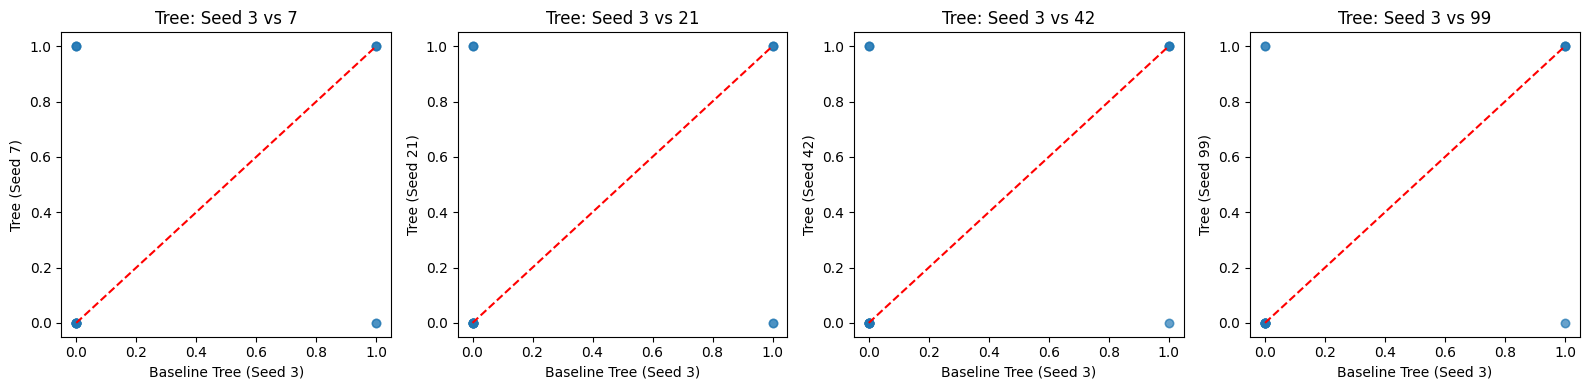

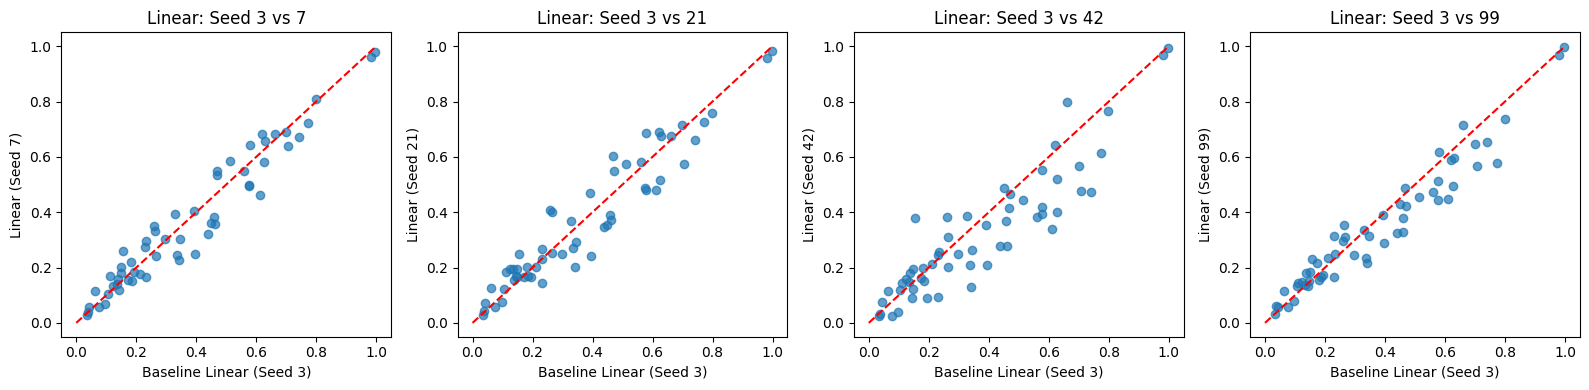

In [ ]:
# Question 4a - Scatterplots

# Decision Tree scatterplots
fig, axes = plt.subplots(1, len(seeds), figsize=(16, 4))
for i, seed in enumerate(seeds):
    axes[i].scatter(treepredbase, tree_predictions[i], alpha=0.2)
    axes[i].plot([0, 1], [0, 1], "r--")
    axes[i].set_xlabel("Baseline Tree (Seed 3)")
    axes[i].set_ylabel(f"Tree (Seed {seed})")
    axes[i].set_title(f"Tree: Seed 3 vs {seed}")
plt.tight_layout()
plt.show()

# Linear Model scatterplots
fig, axes = plt.subplots(1, len(seeds), figsize=(16, 4))
for i, seed in enumerate(seeds):
    axes[i].scatter(linearpredbase, linear_predictions[i], alpha=0.7)
    axes[i].plot([0, 1], [0, 1], "r--")
    axes[i].set_xlabel("Baseline Linear (Seed 3)")
    axes[i].set_ylabel(f"Linear (Seed {seed})")
    axes[i].set_title(f"Linear: Seed 3 vs {seed}")
plt.tight_layout()
plt.show()

For the logistic regression models, the predicted probabilities follow the diagonal $y = x$ line closely across all four seeds, so their predictions appear reasonably similar. For the decision trees, because the trees output probabilities of only 0 and 1, all points fall at the four corners (0, 0), (0, 1), (1, 0), and (1, 1), with noticeable off-diagonal points at (0, 1) and (1, 0) where the models disagree, so the tree predictions are much less similar across splits.

In [ ]:

# Question 4b - Compute Correlation

print("Decision Tree Correlations with Baseline (Seed 3):")
for i, seed in enumerate(seeds):
    tree_corr = np.corrcoef(treepredbase, tree_predictions[i])[0, 1]
    print(f"Seed {seed}: {tree_corr:.4f}")

print("\nLinear Model Correlations with Baseline (Seed 3):")
for i, seed in enumerate(seeds):
    linear_corr = np.corrcoef(linearpredbase, linear_predictions[i])[0, 1]
    print(f"Seed {seed}: {linear_corr:.4f}")

Decision Tree Correlations with Baseline (Seed 3):
Seed 7: 0.2804
Seed 21: 0.3357
Seed 42: 0.4358
Seed 99: 0.4936

Linear Model Correlations with Baseline (Seed 3):
Seed 7: 0.9690
Seed 21: 0.9552
Seed 42: 0.9105
Seed 99: 0.9662


The logistic regression models are very highly correlated with the baseline model across all four seeds (ranging from 0.9105 to 0.9690), meaning their predicted probabilities stay very consistent across different train/test splits. In contrast, the decision tree models only have weak correlations with the baseline tree (ranging from 0.2804 to 0.4936), showing that their predictions vary substantially when the training split changes.

In [ ]:
# Question 4c - Simple Linear Regression
from sklearn.linear_model import LinearRegression

print("Decision Tree Regressions (Alternative vs Baseline Seed 3):")
X_tree_base = treepredbase.reshape(-1, 1)
for i, seed in enumerate(seeds):
    reg = LinearRegression().fit(X_tree_base, tree_predictions[i])
    r2 = reg.score(X_tree_base, tree_predictions[i])
    print(f"Seed {seed}: intercept = {reg.intercept_:.4f}, slope = {reg.coef_[0]:.4f}, R^2 = {r2:.4f}")

print("\nLinear Model Regressions (Alternative vs Baseline Seed 3):")
X_linear_base = linearpredbase.reshape(-1, 1)
for i, seed in enumerate(seeds):
    reg = LinearRegression().fit(X_linear_base, linear_predictions[i])
    r2 = reg.score(X_linear_base, linear_predictions[i])
    print(f"Seed {seed}: intercept = {reg.intercept_:.4f}, slope = {reg.coef_[0]:.4f}, R^2 = {r2:.4f}")

Decision Tree Regressions (Alternative vs Baseline Seed 3):
Seed 7: intercept = 0.3158, slope = 0.2953, R^2 = 0.0786
Seed 21: intercept = 0.2632, slope = 0.3480, R^2 = 0.1127
Seed 42: intercept = 0.2632, slope = 0.4591, R^2 = 0.1899
Seed 99: intercept = 0.2105, slope = 0.5117, R^2 = 0.2437

Linear Model Regressions (Alternative vs Baseline Seed 3):
Seed 7: intercept = 0.0142, slope = 0.9379, R^2 = 0.9389
Seed 21: intercept = 0.0274, slope = 0.9147, R^2 = 0.9124
Seed 42: intercept = 0.0150, slope = 0.8238, R^2 = 0.8291
Seed 99: intercept = 0.0244, slope = 0.8646, R^2 = 0.9335


For the logistic regression models, the intercepts are very close to 0 (0.0142 to 0.0274), the slopes are close to 1 (0.8238 to 0.9379), and the $R^2$ values are high and close to 1 (0.8291 to 0.9389), confirming strong agreement across splits. For the decision trees, the intercepts are noticeably above 0 (0.2105 to 0.3158), the slopes are far below 1 (0.2953 to 0.5117), and the $R^2$ values are low (0.0786 to 0.2437), showing much less prediction stability across splits.

In [ ]:
# Question 5 - Coefficients and trees side by side for all five seeds
# Refitting with the same seeds gives the same models as in Questions 2 and 3

all_seeds = [3] + seeds
coefficients = {}

for seed in all_seeds:
    X_train, X_test, y_train, y_test = train_test_split(X_pool, y_pool, test_size=0.2, random_state=seed, stratify=y_pool)
    tree_new = DecisionTreeClassifier(random_state=seed).fit(X_train, y_train)
    linear_new = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_train, y_train)
    coefficients[seed] = linear_new.named_steps["logisticregression"].coef_[0]

    # First split of each tree
    first = X.columns[tree_new.tree_.feature[0]]
    print(f"Seed {seed}: tree splits first on {first} <= {tree_new.tree_.threshold[0]:.2f}, depth = {tree_new.get_depth()}, leaves = {tree_new.get_n_leaves()}")

print("\nLogistic regression coefficients by seed:")
print(pd.DataFrame(coefficients, index=X.columns).round(3))

Seed 3: tree splits first on ejection_fraction <= 27.50, depth = 13, leaves = 41
Seed 7: tree splits first on ejection_fraction <= 27.50, depth = 11, leaves = 41
Seed 21: tree splits first on serum_creatinine <= 1.15, depth = 13, leaves = 41
Seed 42: tree splits first on serum_creatinine <= 1.65, depth = 11, leaves = 36
Seed 99: tree splits first on ejection_fraction <= 27.50, depth = 11, leaves = 38

Logistic regression coefficients by seed:
                             3      7      21     42     99
age                       0.652  0.469  0.443  0.374  0.337
anaemia                   0.419  0.253  0.347  0.208  0.334
creatinine_phosphokinase  0.510  0.445  0.315  0.530  0.444
diabetes                  0.186  0.070  0.091 -0.131  0.120
ejection_fraction        -0.634 -0.722 -0.660 -0.767 -0.659
high_blood_pressure       0.319  0.258  0.189  0.075  0.169
platelets                -0.125 -0.112 -0.089 -0.121 -0.099
serum_creatinine          0.602  0.475  0.437  0.732  0.688
serum_sodium 

The logistic regressions do. Across the five splits in the table above, every coefficient keeps its sign except the small ones for diabetes and smoking, and ejection fraction is always one of the two largest in absolute value. Their predictions for the common set correlate with the seed-3 model at 0.9105 to 0.9690. The trees do not. They are similar in size, but three of them split first on ejection fraction and the other two on serum creatinine, and their predictions correlate with the seed-3 tree at only 0.2804 to 0.4936. A fully grown tree fits the quirks of its own training sample, so it is fragile, while the regression coefficients are estimated from all the training patients together.

Question 6

True for the logistic regressions and false for the trees. The logistic regressions look somewhat different from split to split, since the serum creatinine coefficient ranges from 0.437 to 0.732 and diabetes and smoking change sign, yet their predictions correlate at 0.9105 or more, with intercepts near zero, slopes from 0.8238 to 0.9379 and R² from 0.8291 to 0.9389. The trees are about the same size but predict very differently. Their predictions correlate with the seed-3 tree at 0.4936 at most, the slopes are only 0.2953 to 0.5117 and R² is at most 0.2437, because a fully grown tree predicts only 0 or 1, as the scatterplots show, and a different training sample flips many of those calls.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 0d04ce95a66f827904d2c1c7c423dcb7d0a9e021
- **AI tool and model used:** GPT 5.6 Sol

### *Prompts used

1. Can you provide me a concise list of specific changes to make to fix any issues in phase 1. Must be a correction that is wrong, not a minor tweak or adjustment just to make a change.
2. Are there any mall improvements to make then?

### *AI-proposed changes


First Prompt:
1. No changes found, entire notebook is correct.

Second Prompt:
1. Fix the Q3 comment — it says predictions are saved on “the same test data from Question 2,” but the code uses X_common. Change it to say predictions are on the held-out common set.

2. Label coefficients with feature names in Q3 — right now you print a raw array. Print them with X.columns (or a small DataFrame) so the sign/pattern claims are easier to verify.

3. Tree scatterplot readability — bump alpha (e.g. to 0.5) and/or add a little jitter so the corner points are easier to see; with alpha=0.2 the 0/1 grid is hard to read.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Fix Q3 comment (`X_common` vs “test data from Question 2”) | Accept | The comment is factually wrong: predictions are stored from `X_common`, not Q2’s `X_test`. Updating the comment makes the notebook match the code and avoids confusing the Q4 comparison set. |
| 2. Label Q3 coefficients with feature names | Accept | The raw `coef_` array is hard to read against the Q3 writeup (e.g., ejection fraction, diabetes, smoking). Printing `pd.Series(..., index=X.columns)` or a small DataFrame lets us verify sign/magnitude claims directly from the output. |
| 3. Improve tree scatterplot readability (`alpha` / jitter) | Accept | Fully grown trees only predict 0/1, so points stack at four corners; `alpha=0.2` makes disagreement hard to see. Raising `alpha` (and optional jitter) makes off-diagonal disagreement clearer without changing the underlying predictions or conclusions. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Question 1 - Cleaning the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/L03-tree-stability/data/heart_failure/heart_failure_clinical_records_dataset.csv")

#Checking for the shape of the data as well as duplicates and null values.
print("Shape:",  df.shape)
print("Number of missing values:" ,df.isna().sum().sum())
print("Number of duplicated values:", df.duplicated().sum())
print("Neither duplicated values nor missing values were found")

# Serum creatinine of exactly 1.18 or 1.83 shows up only for survivors or only for deaths,
# so those values were filled in from the outcome itself; drop these rows
filled = df["serum_creatinine"].isin([1.18, 1.83])
print("Rows with serum creatinine of 1.18 or 1.83:", filled.sum())
print(pd.crosstab(df.loc[filled, "serum_creatinine"], df.loc[filled, "DEATH_EVENT"]))
df = df[~filled]
print("Shape after cleaning:", df.shape)

X = df.drop(columns=["DEATH_EVENT", "time"])
y = df["DEATH_EVENT"]

#features and target
print("\nFeatures:", X.columns.tolist())
print("Target:", y.name)

Shape: (299, 13)
Number of missing values: 0
Number of duplicated values: 0
Neither duplicated values nor missing values were found
Rows with serum creatinine of 1.18 or 1.83: 19
DEATH_EVENT        0  1
serum_creatinine       
1.18              11  0
1.83               0  8
Shape after cleaning: (280, 13)

Features: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']
Target: DEATH_EVENT


In [ ]:
# Question 2 - Train-Test Split and Linear model

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

X_pool, X_common, y_pool, y_common = train_test_split(X, y, test_size=0.2, random_state=2026, stratify=y) #For reproducibility

# Train-Test Split for a specific seed.
seed = 3
X_train, X_test, y_train, y_test = train_test_split(X_pool, y_pool, test_size=0.2, random_state=seed, stratify=y_pool)

# Fitting the tree and the linear model on the training data.
tree = DecisionTreeClassifier(random_state=seed)
tree.fit(X_train, y_train)
linear = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
linear.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
linear_pred = linear.predict(X_test)

# Accuracy Score
print("Decision Tree Accuracy:", accuracy_score(y_test, tree_pred))
print("Logistic Regression Accuracy:", accuracy_score(y_test, linear_pred))

# Predictions
treepredbase = tree.predict_proba(X_common)[:, 1]
linearpredbase = linear.predict_proba(X_common)[:,1]

Decision Tree Accuracy: 0.6666666666666666
Logistic Regression Accuracy: 0.6888888888888889


In [ ]:
# Question 3

seeds = [7, 21, 42, 99]

tree_predictions = []
linear_predictions = []

for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X_pool,
        y_pool,
        test_size=0.2,
        random_state=seed,
        stratify=y_pool
    )

    # Train the decision tree
    tree_new = DecisionTreeClassifier(random_state=seed)
    tree_new.fit(X_train, y_train)

    # logistic regression
    linear_new = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )
    linear_new.fit(X_train, y_train)

    # Print accuracy
    print("Seed:", seed)
    print("Tree accuracy:", tree_new.score(X_test, y_test))
    print("Linear accuracy:", linear_new.score(X_test, y_test))
    print("Tree depth:", tree_new.get_depth())
    print("Number of leaves:", tree_new.get_n_leaves())
    print()

    # Save predictions on the held-out common set (X_common)
    tree_predictions.append(tree_new.predict_proba(X_common)[:, 1])
    linear_predictions.append(linear_new.predict_proba(X_common)[:, 1])

    # Print the linear model coefficients
    print("Linear coefficients:")
    print(pd.Series(
    linear_new.named_steps["logisticregression"].coef_[0],
    index=X.columns
))

Seed: 7
Tree accuracy: 0.5777777777777777
Linear accuracy: 0.8
Tree depth: 11
Number of leaves: 41

Linear coefficients:
age                         0.469100
anaemia                     0.252800
creatinine_phosphokinase    0.445010
diabetes                    0.070499
ejection_fraction          -0.722056
high_blood_pressure         0.258260
platelets                  -0.112306
serum_creatinine            0.475408
serum_sodium               -0.318853
sex                        -0.249783
smoking                    -0.058070
dtype: float64
Seed: 21
Tree accuracy: 0.6444444444444445
Linear accuracy: 0.6888888888888889
Tree depth: 13
Number of leaves: 41

Linear coefficients:
age                         0.442754
anaemia                     0.346660
creatinine_phosphokinase    0.315222
diabetes                    0.090525
ejection_fraction          -0.659941
high_blood_pressure         0.188990
platelets                  -0.088964
serum_creatinine            0.437404
serum_sodium            

The four seeds created different training and test sets. Tree accuracy ranged from 0.578 to 0.644 and logistic regression accuracy from 0.689 to 0.800. The trees were similar in size but not identical, with depths of 11 to 13 and 36 to 41 leaves. Size alone does not show whether they make the same predictions, which Question 4 checks. The logistic regression coefficients moved but kept their pattern. Ejection fraction had one of the two largest coefficients in absolute value in every split, and only diabetes and smoking changed sign.

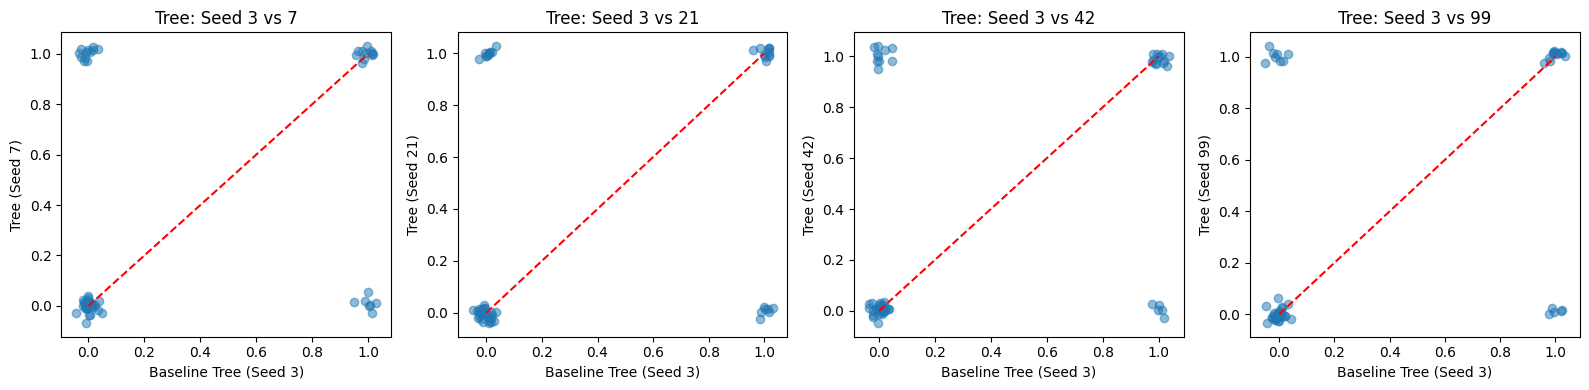

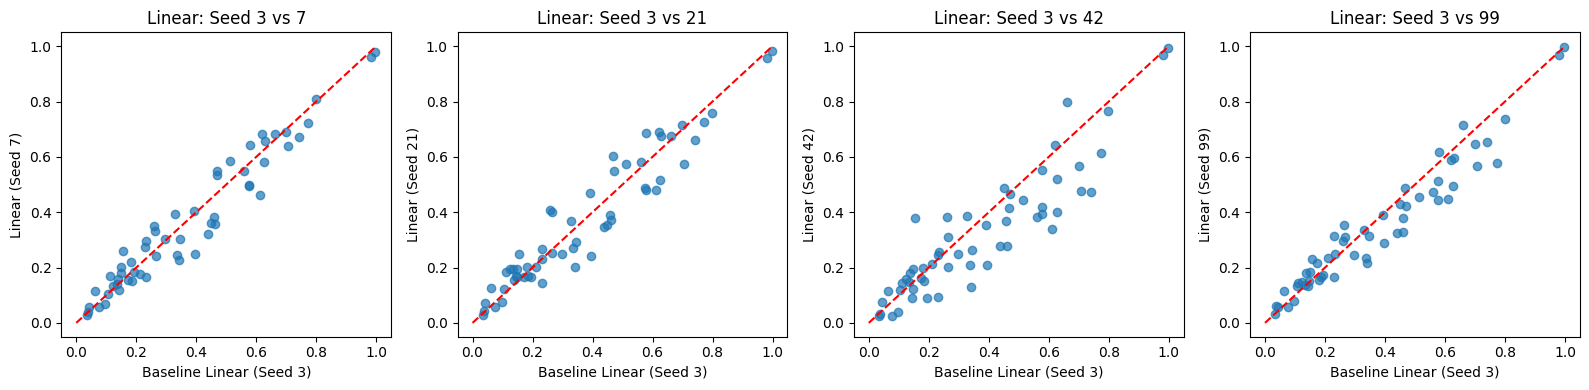

In [ ]:
# Question 4a - Scatterplots

# Decision Tree scatterplots
fig, axes = plt.subplots(1, len(seeds), figsize=(16, 4))
for i, seed in enumerate(seeds):
    x = treepredbase + np.random.normal(0, 0.02, size=len(treepredbase))
    y = tree_predictions[i] + np.random.normal(0, 0.02, size=len(tree_predictions[i]))
    axes[i].scatter(x, y, alpha=0.5)
    axes[i].plot([0, 1], [0, 1], "r--")
    axes[i].set_xlabel("Baseline Tree (Seed 3)")
    axes[i].set_ylabel(f"Tree (Seed {seed})")
    axes[i].set_title(f"Tree: Seed 3 vs {seed}")
plt.tight_layout()
plt.show()

# Linear Model scatterplots
fig, axes = plt.subplots(1, len(seeds), figsize=(16, 4))
for i, seed in enumerate(seeds):
    axes[i].scatter(linearpredbase, linear_predictions[i], alpha=0.7)
    axes[i].plot([0, 1], [0, 1], "r--")
    axes[i].set_xlabel("Baseline Linear (Seed 3)")
    axes[i].set_ylabel(f"Linear (Seed {seed})")
    axes[i].set_title(f"Linear: Seed 3 vs {seed}")
plt.tight_layout()
plt.show()

For the logistic regression models, the predicted probabilities follow the diagonal $y = x$ line closely across all four seeds, so their predictions appear reasonably similar. For the decision trees, because the trees output probabilities of only 0 and 1, all points fall at the four corners (0, 0), (0, 1), (1, 0), and (1, 1), with noticeable off-diagonal points at (0, 1) and (1, 0) where the models disagree, so the tree predictions are much less similar across splits.

In [ ]:

# Question 4b - Compute Correlation

print("Decision Tree Correlations with Baseline (Seed 3):")
for i, seed in enumerate(seeds):
    tree_corr = np.corrcoef(treepredbase, tree_predictions[i])[0, 1]
    print(f"Seed {seed}: {tree_corr:.4f}")

print("\nLinear Model Correlations with Baseline (Seed 3):")
for i, seed in enumerate(seeds):
    linear_corr = np.corrcoef(linearpredbase, linear_predictions[i])[0, 1]
    print(f"Seed {seed}: {linear_corr:.4f}")

Decision Tree Correlations with Baseline (Seed 3):
Seed 7: 0.2804
Seed 21: 0.3357
Seed 42: 0.4358
Seed 99: 0.4936

Linear Model Correlations with Baseline (Seed 3):
Seed 7: 0.9690
Seed 21: 0.9552
Seed 42: 0.9105
Seed 99: 0.9662


The logistic regression models are very highly correlated with the baseline model across all four seeds (ranging from 0.9105 to 0.9690), meaning their predicted probabilities stay very consistent across different train/test splits. In contrast, the decision tree models only have weak correlations with the baseline tree (ranging from 0.2804 to 0.4936), showing that their predictions vary substantially when the training split changes.

In [ ]:
# Question 4c - Simple Linear Regression
from sklearn.linear_model import LinearRegression

print("Decision Tree Regressions (Alternative vs Baseline Seed 3):")
X_tree_base = treepredbase.reshape(-1, 1)
for i, seed in enumerate(seeds):
    reg = LinearRegression().fit(X_tree_base, tree_predictions[i])
    r2 = reg.score(X_tree_base, tree_predictions[i])
    print(f"Seed {seed}: intercept = {reg.intercept_:.4f}, slope = {reg.coef_[0]:.4f}, R^2 = {r2:.4f}")

print("\nLinear Model Regressions (Alternative vs Baseline Seed 3):")
X_linear_base = linearpredbase.reshape(-1, 1)
for i, seed in enumerate(seeds):
    reg = LinearRegression().fit(X_linear_base, linear_predictions[i])
    r2 = reg.score(X_linear_base, linear_predictions[i])
    print(f"Seed {seed}: intercept = {reg.intercept_:.4f}, slope = {reg.coef_[0]:.4f}, R^2 = {r2:.4f}")

Decision Tree Regressions (Alternative vs Baseline Seed 3):
Seed 7: intercept = 0.3158, slope = 0.2953, R^2 = 0.0786
Seed 21: intercept = 0.2632, slope = 0.3480, R^2 = 0.1127
Seed 42: intercept = 0.2632, slope = 0.4591, R^2 = 0.1899
Seed 99: intercept = 0.2105, slope = 0.5117, R^2 = 0.2437

Linear Model Regressions (Alternative vs Baseline Seed 3):
Seed 7: intercept = 0.0142, slope = 0.9379, R^2 = 0.9389
Seed 21: intercept = 0.0274, slope = 0.9147, R^2 = 0.9124
Seed 42: intercept = 0.0150, slope = 0.8238, R^2 = 0.8291
Seed 99: intercept = 0.0244, slope = 0.8646, R^2 = 0.9335


For the logistic regression models, the intercepts are very close to 0 (0.0142 to 0.0274), the slopes are close to 1 (0.8238 to 0.9379), and the $R^2$ values are high and close to 1 (0.8291 to 0.9389), confirming strong agreement across splits. For the decision trees, the intercepts are noticeably above 0 (0.2105 to 0.3158), the slopes are far below 1 (0.2953 to 0.5117), and the $R^2$ values are low (0.0786 to 0.2437), showing much less prediction stability across splits.

In [ ]:
# Question 5 - Coefficients and trees side by side for all five seeds
# Refitting with the same seeds gives the same models as in Questions 2 and 3

all_seeds = [3] + seeds
coefficients = {}

for seed in all_seeds:
    X_train, X_test, y_train, y_test = train_test_split(X_pool, y_pool, test_size=0.2, random_state=seed, stratify=y_pool)
    tree_new = DecisionTreeClassifier(random_state=seed).fit(X_train, y_train)
    linear_new = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_train, y_train)
    coefficients[seed] = linear_new.named_steps["logisticregression"].coef_[0]

    # First split of each tree
    first = X.columns[tree_new.tree_.feature[0]]
    print(f"Seed {seed}: tree splits first on {first} <= {tree_new.tree_.threshold[0]:.2f}, depth = {tree_new.get_depth()}, leaves = {tree_new.get_n_leaves()}")

print("\nLogistic regression coefficients by seed:")
print(pd.DataFrame(coefficients, index=X.columns).round(3))

Seed 3: tree splits first on ejection_fraction <= 27.50, depth = 13, leaves = 41
Seed 7: tree splits first on ejection_fraction <= 27.50, depth = 11, leaves = 41
Seed 21: tree splits first on serum_creatinine <= 1.15, depth = 13, leaves = 41
Seed 42: tree splits first on serum_creatinine <= 1.65, depth = 11, leaves = 36
Seed 99: tree splits first on ejection_fraction <= 27.50, depth = 11, leaves = 38

Logistic regression coefficients by seed:
                             3      7      21     42     99
age                       0.652  0.469  0.443  0.374  0.337
anaemia                   0.419  0.253  0.347  0.208  0.334
creatinine_phosphokinase  0.510  0.445  0.315  0.530  0.444
diabetes                  0.186  0.070  0.091 -0.131  0.120
ejection_fraction        -0.634 -0.722 -0.660 -0.767 -0.659
high_blood_pressure       0.319  0.258  0.189  0.075  0.169
platelets                -0.125 -0.112 -0.089 -0.121 -0.099
serum_creatinine          0.602  0.475  0.437  0.732  0.688
serum_sodium 

The logistic regressions do. Across the five splits in the table above, every coefficient keeps its sign except the small ones for diabetes and smoking, and ejection fraction is always one of the two largest in absolute value. Their predictions for the common set correlate with the seed-3 model at 0.9105 to 0.9690. The trees do not. They are similar in size, but three of them split first on ejection fraction and the other two on serum creatinine, and their predictions correlate with the seed-3 tree at only 0.2804 to 0.4936. A fully grown tree fits the quirks of its own training sample, so it is fragile, while the regression coefficients are estimated from all the training patients together.

Question 6

True for the logistic regressions and false for the trees. The logistic regressions look somewhat different from split to split, since the serum creatinine coefficient ranges from 0.437 to 0.732 and diabetes and smoking change sign, yet their predictions correlate at 0.9105 or more, with intercepts near zero, slopes from 0.8238 to 0.9379 and R² from 0.8291 to 0.9389. The trees are about the same size but predict very differently. Their predictions correlate with the seed-3 tree at 0.4936 at most, the slopes are only 0.2953 to 0.5117 and R² is at most 0.2437, because a fully grown tree predicts only 0 or 1, as the scatterplots show, and a different training sample flips many of those calls.

### *Reflection on AI assistance
In your own words without generative AI.

The main Phase 2 improvements were small clarity and presentation fixes, not changes to the model or our approach. This was because the AI found that our outputs were correct and didn't need any substantive change to become correct. Of the changes we made they just were making it easier to read.First, we corrected the Question 3 comment so it correctly says predictions are saved on the held-out common set X_common, not on Question 2’s test set. Second, we printed the logistic regression coefficients with feature names so the patterns discussed in the writeup are easier to understand and see. Third, we increased the tree scatterplot alpha and added light jitter so the stacked 0/1 predictions are easier to see. A limitation of the AI assistance was that when we first asked only for real errors, it reported no substantive analytical mistakes. That was good to know, but it meant Phase 2 improvements were polish rather than fixes to wrong results. We confirmed the changes are valid by rerunning the code and checking if the regression slopes/intercepts/$R^2$, and coefficient patterns still match the Phase 1 numbers. One remaining concern is that jitter is random, so the tree plots can look slightly different each run even though the underlying predictions are fixed.
